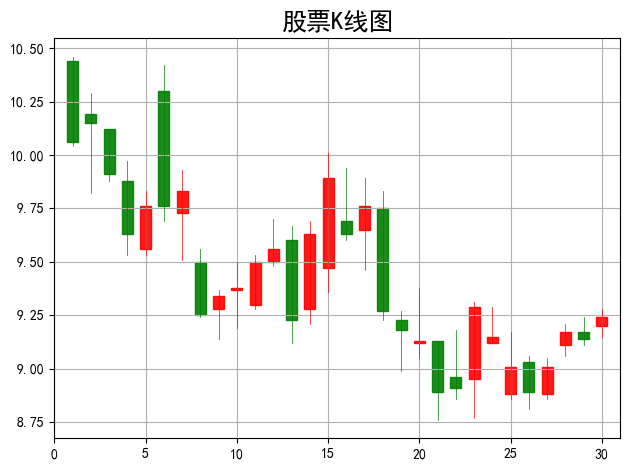

In [2]:
#自回归 股价预测
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import mpl_finance as mpf
# from matplotlib.finance import candlestick_ohlc


if __name__ == "__main__":
    mpl.rcParams['font.sans-serif'] = [u'SimHei']
    mpl.rcParams['axes.unicode_minus'] = False

    np.set_printoptions(suppress=True, linewidth=100, edgeitems=5)
    data = np.loadtxt('./data/7.SH600000.txt', dtype=float, delimiter='\t', skiprows=2, usecols=(1, 2, 3, 4))
    data = data[:30]
    N = len(data)

    t = np.arange(1, N+1).reshape((-1, 1))
    data = np.hstack((t, data))

    fig, ax = plt.subplots(facecolor='w')
    fig.subplots_adjust(bottom=0.2)
    mpf.candlestick_ohlc(ax, data, width=0.6, colorup='r', colordown='g', alpha=0.9)
    plt.xlim((0, N+1))
    plt.grid(visible=True)
    plt.title(u'股票K线图', fontsize=18)
    plt.tight_layout()
    plt.show()

In [6]:
with open("../data/7.SH600000.txt") as f:
    print(f.readline())

FileNotFoundError: [Errno 2] No such file or directory: '../data/7.SH600000.txt'

In [4]:
if __name__=="__main__":
    #日期    开盘    最高    最低    收盘    成交量    成交额
    price =np.loadtxt('../data/sh_600000.txt',delimiter='\t',skiprows=2,usecols=(4,))
    print("原始价格：\n",price )
    n= 100 #阶数
    y=price[n:] 
    m = len(y) #样本个数
    print("预测价格：\n"，y) 
    X= np.zeros((m,n+1)) 
    for i in range（m):
        x[i]=np.hstack((price[i:i+n],1))
    print("自变量：\n",x)
    theta = np.linalg.lstsq(x, y)[θ] #theta为回归系数
    print(theta)
    show(theta,X, y)
    #预测 
    pn = 20 #预测未来多少天
    X= price[-n:]
    y = np.hstack((price[-n:], np.zeros(pn))) 
    for i in range(pn):
        y[n+i] = np.dot(theta, np.hstack((y[i:n+i], 1))) 
    show_predict(y, pn)


SyntaxError: invalid character '，' (U+FF0C) (1014527777.py, line 8)

线性回归：1阶，系数为： [-12.12113792   3.05477422]
线性回归：2阶，系数为： [-3.23812184 -3.36390661  0.90493645]
线性回归：3阶，系数为： [-3.90207326 -2.61163034  0.66422328  0.02290431]
线性回归：4阶，系数为： [-8.20599769  4.20778207 -2.85304163  0.73902338 -0.05008557]
线性回归：5阶，系数为： [ 21.59733285 -54.12232017  38.43116219 -12.68651476   1.98134176  -0.11572371]
线性回归：6阶，系数为： [ 14.73304784 -37.87317493  23.67462341  -6.07037979   0.42536833   0.06803132  -0.00859246]
线性回归：7阶，系数为： [ 314.30344773 -827.89447315  857.33293588 -465.46543853  144.21883915  -25.67294689    2.44658613   -0.09675941]
线性回归：8阶，系数为： [-1189.50198187  3643.69252927 -4647.93114929  3217.229291   -1325.87429327   334.32879949   -50.57120704     4.21251945    -0.14852104]
Ridge回归：1阶，alpha=0.109854，系数为： [-11.21592213   2.85121516]
Ridge回归：2阶，alpha=0.138950，系数为： [-2.90423989 -3.49931368  0.91803171]
Ridge回归：3阶，alpha=0.068665，系数为： [-3.47165245 -2.85078293  0.69245987  0.02314415]
Ridge回归：4阶，alpha=0.222300，系数为： [-2.84560266 -1.99887417 -0.40628792  0.33863868 -0.02

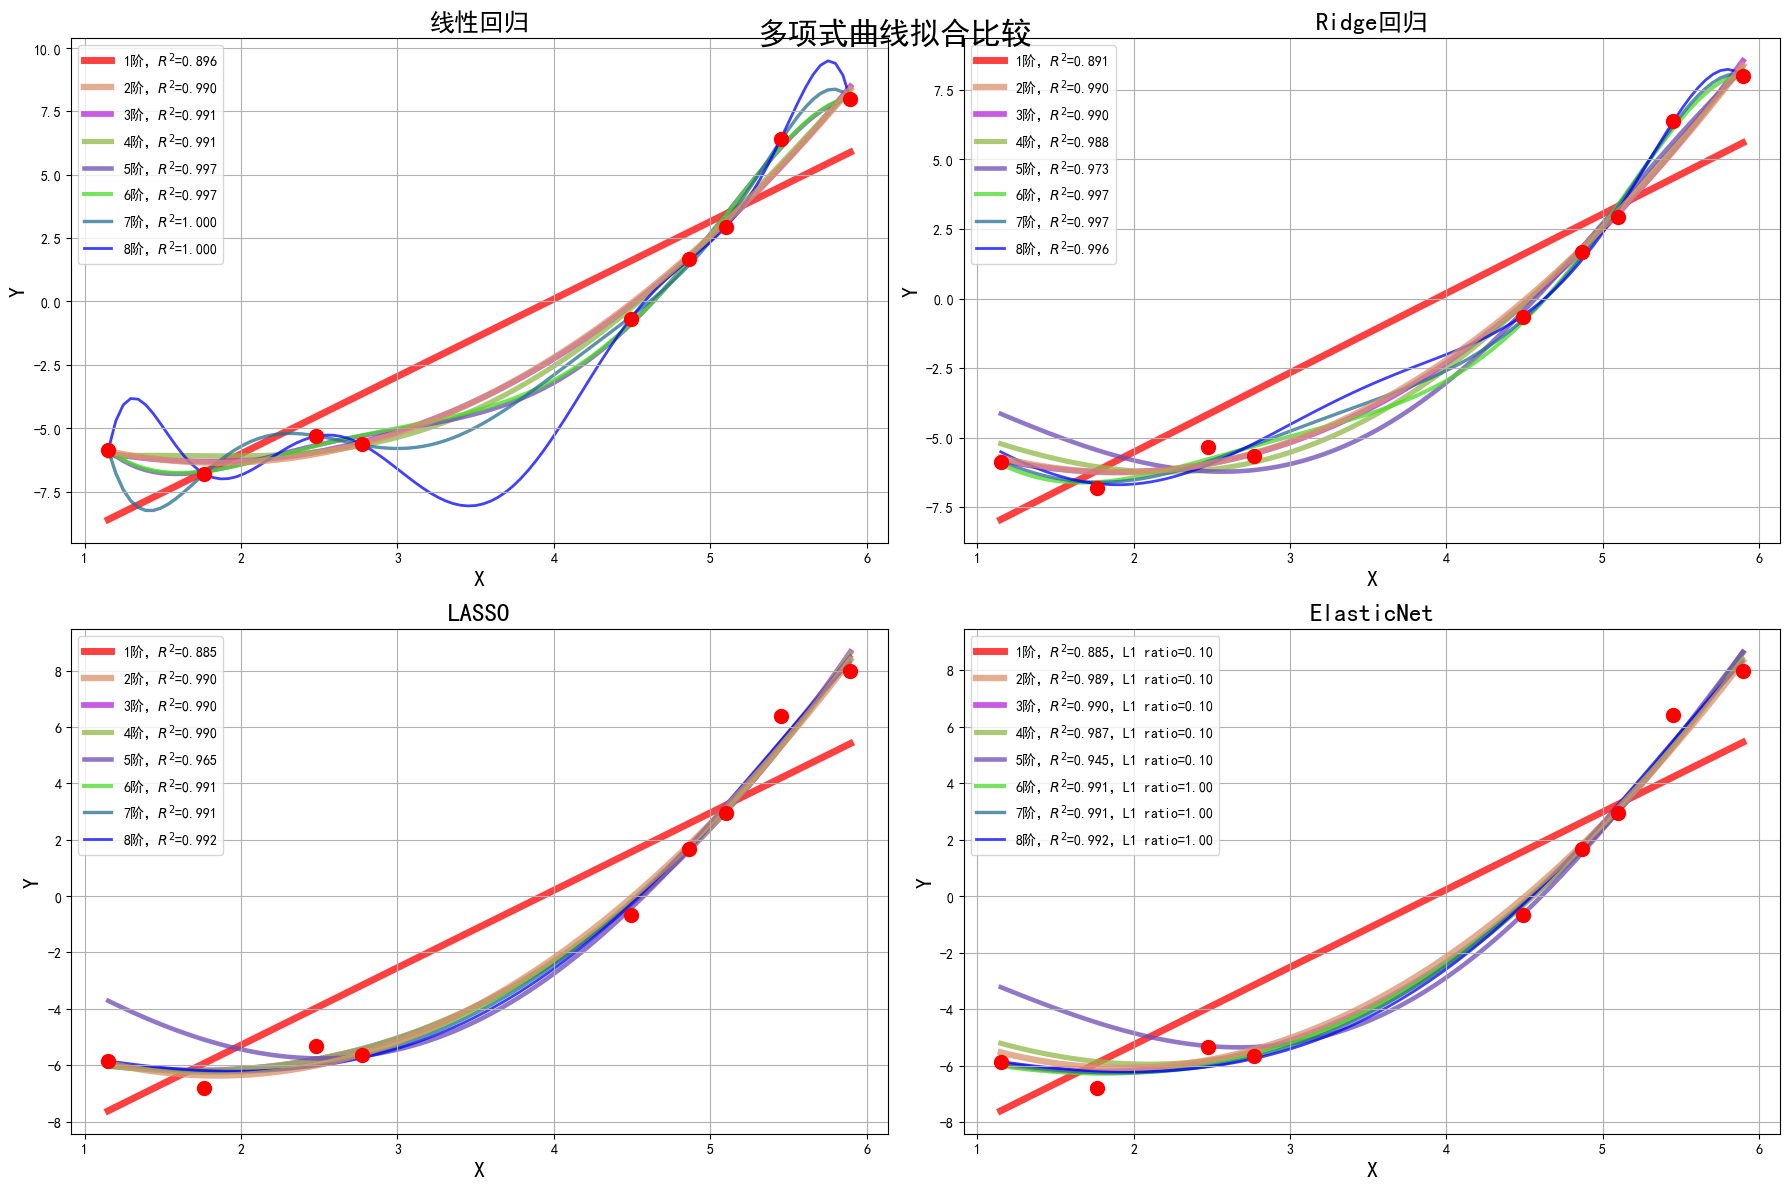

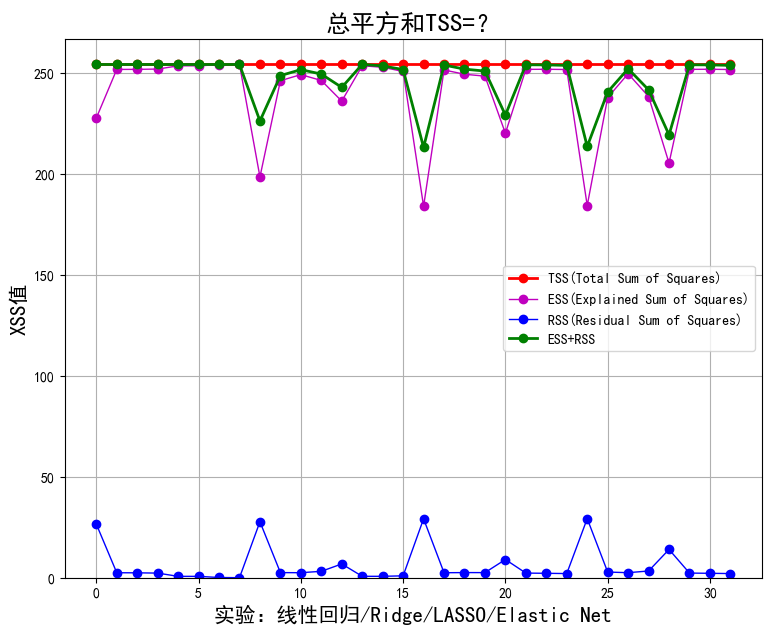

In [5]:
#过拟合示例
import numpy as np
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
import matplotlib as mpl
import warnings

def xss(y, y_hat):
    y = y.ravel()
    y_hat = y_hat.ravel()
    # Version 1
    tss = ((y - np.average(y)) ** 2).sum()
    rss = ((y_hat - y) ** 2).sum()
    ess = ((y_hat - np.average(y)) ** 2).sum()
    r2 = 1 - rss / tss
    # print 'RSS:', rss, '\t ESS:', ess
    # print 'TSS:', tss, 'RSS + ESS = ', rss + ess
    tss_list.append(tss)
    rss_list.append(rss)
    ess_list.append(ess)
    ess_rss_list.append(rss + ess)
    # Version 2
    # tss = np.var(y)
    # rss = np.average((y_hat - y) ** 2)
    # r2 = 1 - rss / tss
    corr_coef = np.corrcoef(y, y_hat)[0, 1]
    return r2, corr_coef


if __name__ == "__main__":
    warnings.filterwarnings("ignore")   # ConvergenceWarning
    np.random.seed(0)
    np.set_printoptions(linewidth=1000)
    N = 9
    x = np.linspace(0, 6, N) + np.random.randn(N)
    x = np.sort(x)
    y = x**2 - 4*x - 3 + np.random.randn(N)
    x.shape = -1, 1
    y.shape = -1, 1

    models = [Pipeline([
        ('poly', PolynomialFeatures()),
        ('linear', LinearRegression(fit_intercept=False))]),
        Pipeline([
            ('poly', PolynomialFeatures()),
            ('linear', RidgeCV(alphas=np.logspace(-3, 2, 50), fit_intercept=False))]),
        Pipeline([
            ('poly', PolynomialFeatures()),
            ('linear', LassoCV(alphas=np.logspace(-3, 2, 50), fit_intercept=False))]),
        Pipeline([
            ('poly', PolynomialFeatures()),
            ('linear', ElasticNetCV(alphas=np.logspace(-3, 2, 50), l1_ratio=[.1, .5, .7, .9, .95, .99, 1],
                                    fit_intercept=False))])
    ]
    mpl.rcParams['font.sans-serif'] = [u'simHei']
    mpl.rcParams['axes.unicode_minus'] = False
    np.set_printoptions(suppress=True)

    plt.figure(figsize=(18, 12), facecolor='w')
    d_pool = np.arange(1, N, 1)  # 阶
    m = d_pool.size
    clrs = []  # 颜色
    for c in np.linspace(16711680, 255, m).astype(int):
        clrs.append("#{:06x}".format(c)) #('#%06x' % c)
    line_width = np.linspace(5, 2, m)
    titles = u'线性回归', u'Ridge回归', u'LASSO', u'ElasticNet'
    tss_list = []
    rss_list = []
    ess_list = []
    ess_rss_list = []
    for t in range(4):
        model = models[t]
        plt.subplot(2, 2, t+1)
        plt.plot(x, y, 'ro', ms=10, zorder=N)
        for i, d in enumerate(d_pool):
            model.set_params(poly__degree=d)
            model.fit(x, y.ravel())
            lin = model.get_params('linear')['linear']
            output = u'%s：%d阶，系数为：' % (titles[t], d)
            if hasattr(lin, 'alpha_'):
                idx = output.find(u'系数')
                output = output[:idx] + (u'alpha=%.6f，' % lin.alpha_) + output[idx:]
            if hasattr(lin, 'l1_ratio_'):   # 根据交叉验证结果，从输入l1_ratio(list)中选择的最优l1_ratio_(float)
                idx = output.find(u'系数')
                output = output[:idx] + (u'l1_ratio=%.6f，' % lin.l1_ratio_) + output[idx:]
            print(output, lin.coef_.ravel() )
            x_hat = np.linspace(x.min(), x.max(), num=100)
            x_hat.shape = -1, 1
            y_hat = model.predict(x_hat)
            s = model.score(x, y)
            r2, corr_coef = xss(y, model.predict(x))
            # print 'R2和相关系数：', r2, corr_coef
            # print 'R2：', s, '\n'
            z = N - 1 if (d == 2) else 0
            label = u'%d阶，$R^2$=%.3f' % (d, s)
            if hasattr(lin, 'l1_ratio_'):
                label += u'，L1 ratio=%.2f' % lin.l1_ratio_
            plt.plot(x_hat, y_hat, color=clrs[i], lw=line_width[i], alpha=0.75, label=label, zorder=z)
        plt.legend(loc='upper left')
        plt.grid(True)
        plt.title(titles[t], fontsize=18)
        plt.xlabel('X', fontsize=16)
        plt.ylabel('Y', fontsize=16)
    plt.tight_layout() #(1, rect=(0, 0, 1, 0.95))
    plt.suptitle(u'多项式曲线拟合比较', fontsize=22)
    plt.show()

    y_max = max(max(tss_list), max(ess_rss_list)) * 1.05
    plt.figure(figsize=(9, 7), facecolor='w')
    t = np.arange(len(tss_list))
    plt.plot(t, tss_list, 'ro-', lw=2, label=u'TSS(Total Sum of Squares)')
    plt.plot(t, ess_list, 'mo-', lw=1, label=u'ESS(Explained Sum of Squares)')
    plt.plot(t, rss_list, 'bo-', lw=1, label=u'RSS(Residual Sum of Squares)')
    plt.plot(t, ess_rss_list, 'go-', lw=2, label=u'ESS+RSS')
    plt.ylim((0, y_max))
    plt.legend(loc='center right')
    plt.xlabel(u'实验：线性回归/Ridge/LASSO/Elastic Net', fontsize=15)
    plt.ylabel(u'XSS值', fontsize=15)
    plt.title(u'总平方和TSS=？', fontsize=18)
    plt.grid(True)
    plt.show()




In [9]:
np.int32(np.linspace(16711680, 255, 3))


array([16711680,  8355967,      255], dtype=int32)

In [13]:
'#%06x' % 8355967
"#{:06x}".format(16711680)

'#ff0000'

In [7]:
t = np.arange(1,17).reshape(4,4)

In [31]:
t = np.array([1,2,3,-1]).reshape(-1,1)
A = t@(t.T)
A@(A.T)

array([[ 15,  30,  45, -15],
       [ 30,  60,  90, -30],
       [ 45,  90, 135, -45],
       [-15, -30, -45,  15]])

In [32]:
np.linalg.det(A@(A.T))

0.0

In [29]:
t

array([[ 1],
       [ 2],
       [ 3],
       [-1]])

In [30]:
A

array([[ 1,  2,  3, -1],
       [ 2,  4,  6, -2],
       [ 3,  6,  9, -3],
       [-1, -2, -3,  1]])

In [21]:
A = np.array([1,1,2])
C = np.array([1,0,0])
B = np.cross(A,C)
C = np.cross(A,B)
arr1 = np.column_stack((A,B,C))
arr2 = np.column_stack((A,np.array([-1, 1, 1]),np.array([-1, -1, 1]) ))


In [27]:
arr2.T@arr2

array([[6, 2, 0],
       [2, 3, 1],
       [0, 1, 3]])

In [28]:
np.linalg.eig(arr2.T@arr2)

EigResult(eigenvalues=array([7.05137424, 1.4659298 , 3.48269595]), eigenvectors=array([[-0.87936655,  0.34661859, -0.32645063],
       [-0.46227167, -0.78579651,  0.41088775],
       [-0.11410244,  0.51222983,  0.85123513]]))

In [39]:
A = np.array([1,1])
i = np.pi/12
rotaion = np.array([[np.cos(i),-np.sin(i)],[np.sin(i),np.cos(i)]])
B = rotaion@A
arr1 = np.column_stack((A,B))
ev,et = np.linalg.eig(arr1)

In [41]:
C = np.array([-1,1]).reshape(-1,1)
C

array([[-1],
       [ 1]])

In [42]:
arr1@C

array([[-0.29289322],
       [ 0.22474487]])

In [40]:
ev,et

(array([0.26400085, 1.96074402]),
 array([[-0.69281098, -0.59275894],
        [ 0.72111923, -0.80537993]]))

In [43]:
A = np.array([1,1])
i = np.pi/12
rotaion = np.array([[np.cos(i),-np.sin(i)],[np.sin(i),np.cos(i)]])
B = rotaion@A * 2
arr1 = np.column_stack((A,B))
np.linalg.eig(arr1)

EigResult(eigenvalues=array([0.33209679, 3.11739296]), eigenvectors=array([[-0.90422886, -0.55541188],
       [ 0.4270482 , -0.8315754 ]]))

In [44]:
np.linalg.norm(et[0,:])

0.9117840899708283

In [45]:
np.linalg.norm(et[1,:])

1.0810410599399398